# Phase 6: Exploratory Data Analysis (EDA)

## Project
Student Performance Prediction Using Machine Learning and Explainable AI

## Objectives
1. Load the cleaned Mathematics and Portuguese datasets.
2. Verify the binary performance target.
3. Analyze Pass and At Risk class distributions.
4. Explore final grade distributions.
5. Investigate academic and behavioral factors.
6. Identify potential patterns for subsequent machine learning experiments.

## Target Definition
- 0 = At Risk (G3 < 10)
- 1 = Pass (G3 >= 10)

The final grade G3 defines the target. It must not be included as an input feature when training a model to predict this target.

In [4]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path
from IPython.display import display

# The notebook is inside the notebooks/ directory.
# Move up one level to reach the project root.
PROJECT_DIR = Path.cwd().parent

DATA_DIR = PROJECT_DIR / "data" / "processed"
RAW_DIR = PROJECT_DIR / "data" / "raw"

print("Project directory:", PROJECT_DIR)
print("Processed data directory:", DATA_DIR)
print("Processed directory exists:", DATA_DIR.exists())

if DATA_DIR.exists():
    print("\nFiles in processed directory:")
    for file in sorted(DATA_DIR.iterdir()):
        if file.is_file():
            print("-", file.name)


Project directory: e:\PROJECTS\Mini Project\Project\Student-Performance-Prediction
Processed data directory: e:\PROJECTS\Mini Project\Project\Student-Performance-Prediction\data\processed
Processed directory exists: True

Files in processed directory:
- student_mat_clean.csv
- student_mat_target.csv
- student_por_clean.csv
- student_por_target.csv


In [5]:

math_target_path = DATA_DIR / "student_mat_target.csv"
por_target_path = DATA_DIR / "student_por_target.csv"

math_clean_path = DATA_DIR / "student_mat_clean.csv"
por_clean_path = DATA_DIR / "student_por_clean.csv"

# Prefer target-labeled files if both exist.
if math_target_path.exists() and por_target_path.exists():
    mat_df = pd.read_csv(math_target_path)
    por_df = pd.read_csv(por_target_path)

    print("Loaded target-labeled datasets.")

elif math_clean_path.exists() and por_clean_path.exists():
    mat_df = pd.read_csv(math_clean_path)
    por_df = pd.read_csv(por_clean_path)

    print("Loaded cleaned datasets.")

else:
    raise FileNotFoundError(
        "Required datasets were not found in data/processed. "
        "Check the filenames printed in Cell 2."
    )

print("Mathematics shape:", mat_df.shape)
print("Portuguese shape:", por_df.shape)


Loaded target-labeled datasets.
Mathematics shape: (395, 34)
Portuguese shape: (649, 34)


In [6]:

PASS_MARK = 10

for name, df in [
    ("Mathematics", mat_df),
    ("Portuguese", por_df)
]:
    if "G3" not in df.columns:
        raise ValueError(f"{name} dataset does not contain G3.")

    expected_target = (df["G3"] >= PASS_MARK).astype(int)

    if "performance" in df.columns:
        if not df["performance"].equals(expected_target):
            raise ValueError(
                f"{name}: existing performance target does not match G3."
            )
    else:
        df["performance"] = expected_target

    assert df["performance"].notna().all()
    assert set(df["performance"].unique()).issubset({0, 1})

# Save the target-labeled datasets
mat_df.to_csv(math_target_path, index=False)
por_df.to_csv(por_target_path, index=False)

print("Target verification successful.")
print("Mathematics missing targets:", mat_df["performance"].isna().sum())
print("Portuguese missing targets:", por_df["performance"].isna().sum())

print("\nMathematics target distribution:")
print(mat_df["performance"].value_counts().sort_index())

print("\nPortuguese target distribution:")
print(por_df["performance"].value_counts().sort_index())


Target verification successful.
Mathematics missing targets: 0
Portuguese missing targets: 0

Mathematics target distribution:
performance
0    130
1    265
Name: count, dtype: int64

Portuguese target distribution:
performance
0    100
1    549
Name: count, dtype: int64


In [7]:

for name, df in [
    ("Mathematics", mat_df),
    ("Portuguese", por_df)
]:
    print(f"\n{'=' * 50}")
    print(name, "dataset")
    print("=" * 50)

    print("\nFirst five rows:")
    display(df.head())

    print("\nDataset information:")
    df.info()

    print("\nDescriptive statistics:")
    display(df.describe(include="all").T)



Mathematics dataset

First five rows:


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3,performance
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,3,4,1,1,3,6,5,6,6,0
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,3,3,1,1,3,4,5,5,6,0
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,3,2,2,3,3,10,7,8,10,1
3,GP,F,15,U,GT3,T,4,2,health,services,...,2,2,1,1,5,2,15,14,15,1
4,GP,F,16,U,GT3,T,3,3,other,other,...,3,2,1,2,5,4,6,10,10,1



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 395 entries, 0 to 394
Data columns (total 34 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   school       395 non-null    object
 1   sex          395 non-null    object
 2   age          395 non-null    int64 
 3   address      395 non-null    object
 4   famsize      395 non-null    object
 5   Pstatus      395 non-null    object
 6   Medu         395 non-null    int64 
 7   Fedu         395 non-null    int64 
 8   Mjob         395 non-null    object
 9   Fjob         395 non-null    object
 10  reason       395 non-null    object
 11  guardian     395 non-null    object
 12  traveltime   395 non-null    int64 
 13  studytime    395 non-null    int64 
 14  failures     395 non-null    int64 
 15  schoolsup    395 non-null    object
 16  famsup       395 non-null    object
 17  paid         395 non-null    object
 18  activities   395 non-null    object
 19  nursery

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
school,395,2,GP,349,NaN,NaN,NaN,NaN,NaN,NaN,NaN
sex,395,2,F,208,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,395.0,NaN,NaN,NaN,16.696203,1.276043,15.0,16.0,17.0,18.0,22.0
address,395,2,U,307,NaN,NaN,NaN,NaN,NaN,NaN,NaN
famsize,395,2,GT3,281,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Pstatus,395,2,T,354,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Medu,395.0,NaN,NaN,NaN,2.749367,1.094735,0.0,2.0,3.0,4.0,4.0
Fedu,395.0,NaN,NaN,NaN,2.521519,1.088201,0.0,2.0,2.0,3.0,4.0
Mjob,395,5,other,141,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Fjob,395,5,other,217,NaN,NaN,NaN,NaN,NaN,NaN,NaN



Portuguese dataset

First five rows:


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,...,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3,performance
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,...,3,4,1,1,3,4,0,11,11,1
1,GP,F,17,U,GT3,T,1,1,at_home,other,...,3,3,1,1,3,2,9,11,11,1
2,GP,F,15,U,LE3,T,1,1,at_home,other,...,3,2,2,3,3,6,12,13,12,1
3,GP,F,15,U,GT3,T,4,2,health,services,...,2,2,1,1,5,0,14,14,14,1
4,GP,F,16,U,GT3,T,3,3,other,other,...,3,2,1,2,5,0,11,13,13,1



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 649 entries, 0 to 648
Data columns (total 34 columns):
 #   Column       Non-Null Count  Dtype 
---  ------       --------------  ----- 
 0   school       649 non-null    object
 1   sex          649 non-null    object
 2   age          649 non-null    int64 
 3   address      649 non-null    object
 4   famsize      649 non-null    object
 5   Pstatus      649 non-null    object
 6   Medu         649 non-null    int64 
 7   Fedu         649 non-null    int64 
 8   Mjob         649 non-null    object
 9   Fjob         649 non-null    object
 10  reason       649 non-null    object
 11  guardian     649 non-null    object
 12  traveltime   649 non-null    int64 
 13  studytime    649 non-null    int64 
 14  failures     649 non-null    int64 
 15  schoolsup    649 non-null    object
 16  famsup       649 non-null    object
 17  paid         649 non-null    object
 18  activities   649 non-null    object
 19  nursery

,count,unique,top,freq,mean,std,min,25%,50%,75%,max
school,649,2,GP,423,NaN,NaN,NaN,NaN,NaN,NaN,NaN
sex,649,2,F,383,NaN,NaN,NaN,NaN,NaN,NaN,NaN
age,649.0,NaN,NaN,NaN,16.744222,1.218138,15.0,16.0,17.0,18.0,22.0
address,649,2,U,452,NaN,NaN,NaN,NaN,NaN,NaN,NaN
famsize,649,2,GT3,457,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Pstatus,649,2,T,569,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Medu,649.0,NaN,NaN,NaN,2.514638,1.134552,0.0,2.0,2.0,4.0,4.0
Fedu,649.0,NaN,NaN,NaN,2.306626,1.099931,0.0,1.0,2.0,3.0,4.0
Mjob,649,5,other,258,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Fjob,649,5,other,367,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [8]:

for name, df in [
    ("Mathematics", mat_df),
    ("Portuguese", por_df)
]:
    print(f"\n{name} dataset")
    print("Duplicate rows:", df.duplicated().sum())

    missing = df.isnull().sum()
    missing = missing[missing > 0]

    if missing.empty:
        print("No missing values found.")
    else:
        print("Columns with missing values:")
        display(missing.sort_values(ascending=False))



Mathematics dataset
Duplicate rows: 0
No missing values found.

Portuguese dataset
Duplicate rows: 0
No missing values found.



Mathematics: performance distribution


,Class,Count,Percentage
0,At Risk,130,32.91
1,Pass,265,67.09


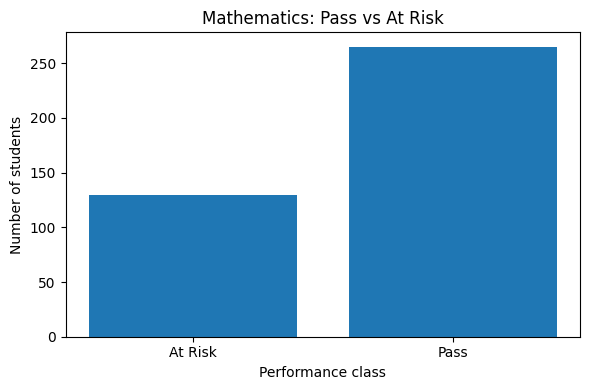


Portuguese: performance distribution


,Class,Count,Percentage
0,At Risk,100,15.41
1,Pass,549,84.59


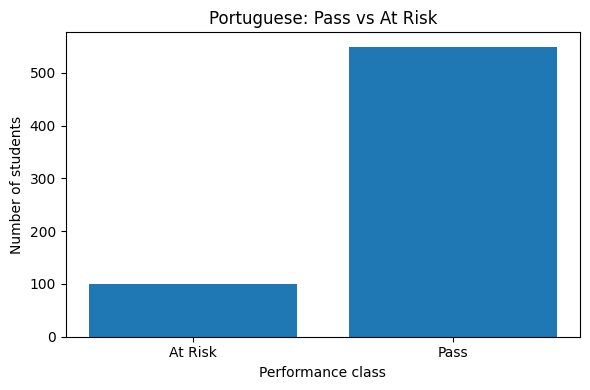

In [9]:

datasets = {
    "Mathematics": mat_df,
    "Portuguese": por_df
}

for name, df in datasets.items():
    counts = (
        df["performance"]
        .value_counts()
        .reindex([0, 1], fill_value=0)
    )

    percentages = counts / len(df) * 100

    summary = pd.DataFrame({
        "Class": ["At Risk", "Pass"],
        "Count": [counts[0], counts[1]],
        "Percentage": percentages.values.round(2)
    })

    print(f"\n{name}: performance distribution")
    display(summary)

    plt.figure(figsize=(6, 4))
    plt.bar(["At Risk", "Pass"], counts.values)
    plt.title(f"{name}: Pass vs At Risk")
    plt.xlabel("Performance class")
    plt.ylabel("Number of students")
    plt.tight_layout()
    plt.show()


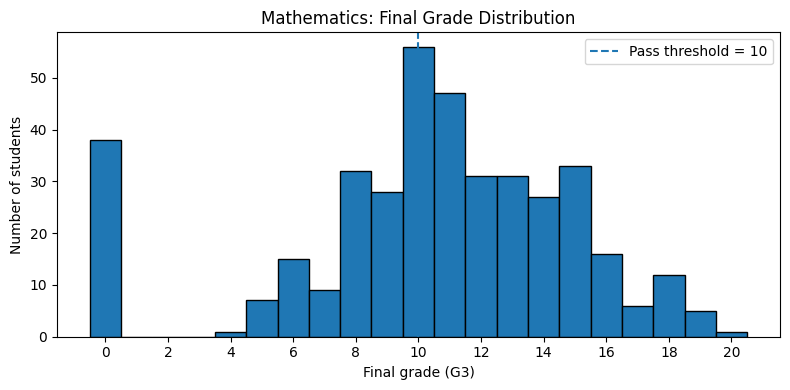

Mathematics grade statistics:


count    395.000000
mean      10.415190
std        4.581443
min        0.000000
25%        8.000000
50%       11.000000
75%       14.000000
max       20.000000
Name: G3, dtype: float64

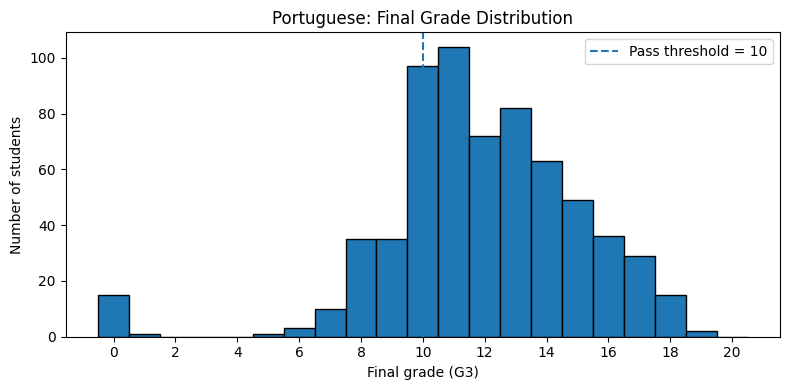

Portuguese grade statistics:


count    649.000000
mean      11.906009
std        3.230656
min        0.000000
25%       10.000000
50%       12.000000
75%       14.000000
max       19.000000
Name: G3, dtype: float64

In [10]:

for name, df in datasets.items():
    plt.figure(figsize=(8, 4))

    plt.hist(
        df["G3"],
        bins=np.arange(-0.5, 21.5, 1),
        edgecolor="black"
    )

    plt.axvline(
        10,
        linestyle="--",
        label="Pass threshold = 10"
    )

    plt.title(f"{name}: Final Grade Distribution")
    plt.xlabel("Final grade (G3)")
    plt.ylabel("Number of students")
    plt.xticks(range(0, 21, 2))
    plt.legend()
    plt.tight_layout()
    plt.show()

    print(f"{name} grade statistics:")
    display(df["G3"].describe())


In [11]:

selected_features = [
    "studytime",
    "failures",
    "absences",
    "famrel",
    "freetime",
    "goout",
    "health"
]

for name, df in datasets.items():
    available_features = [
        col for col in selected_features
        if col in df.columns
    ]

    print(f"\n{name}: mean feature values by performance")
    display(
        df.groupby("performance")[available_features]
        .mean()
        .rename(index={0: "At Risk", 1: "Pass"})
        .round(2)
    )



Mathematics: mean feature values by performance


,studytime,failures,absences,famrel,freetime,goout,health
performance,,,,,,,
At Risk,1.95,0.69,6.76,3.88,3.26,3.40,3.68
Pass,2.08,0.16,5.19,3.97,3.22,2.97,3.49



Portuguese: mean feature values by performance


,studytime,failures,absences,famrel,freetime,goout,health
performance,,,,,,,
At Risk,1.61,0.75,4.61,3.83,3.41,3.37,3.57
Pass,1.99,0.13,3.49,3.95,3.14,3.15,3.53


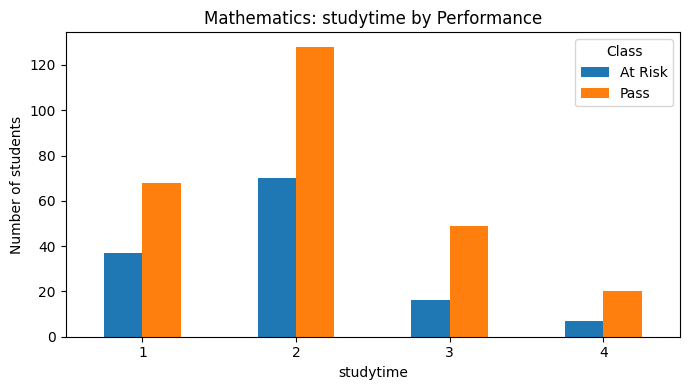

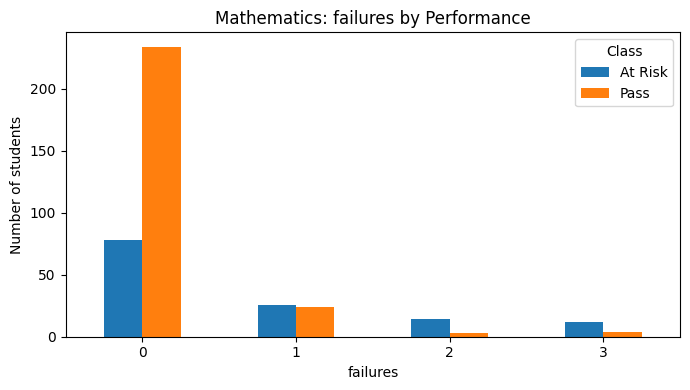

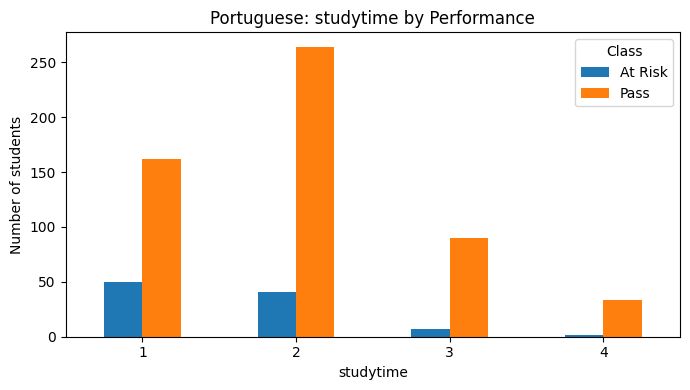

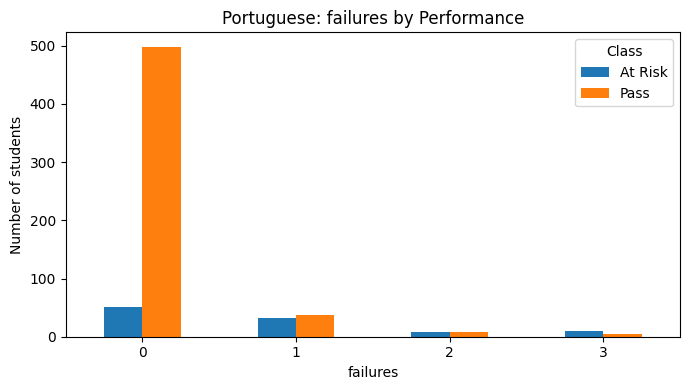

In [12]:

for name, df in datasets.items():
    available_features = [
        col for col in ["studytime", "failures"]
        if col in df.columns
    ]

    for feature in available_features:
        grouped = (
            df.groupby([feature, "performance"])
            .size()
            .unstack(fill_value=0)
            .reindex(columns=[0, 1], fill_value=0)
        )

        grouped.columns = ["At Risk", "Pass"]

        grouped.plot(
            kind="bar",
            figsize=(7, 4)
        )

        plt.title(f"{name}: {feature} by Performance")
        plt.xlabel(feature)
        plt.ylabel("Number of students")
        plt.xticks(rotation=0)
        plt.legend(title="Class")
        plt.tight_layout()
        plt.show()



Mathematics: numerical feature correlations


,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,performance
age,1.00,-0.16,-0.16,0.07,-0.00,0.24,0.05,0.02,0.13,0.13,0.12,-0.06,0.18,-0.06,-0.14,-0.18
Medu,-0.16,1.00,0.62,-0.17,0.06,-0.24,-0.00,0.03,0.06,0.02,-0.05,-0.05,0.10,0.21,0.22,0.12
Fedu,-0.16,0.62,1.00,-0.16,-0.01,-0.25,-0.00,-0.01,0.04,0.00,-0.01,0.01,0.02,0.19,0.16,0.11
traveltime,0.07,-0.17,-0.16,1.00,-0.10,0.09,-0.02,-0.02,0.03,0.14,0.13,0.01,-0.01,-0.09,-0.15,-0.04
studytime,-0.00,0.06,-0.01,-0.10,1.00,-0.17,0.04,-0.14,-0.06,-0.20,-0.25,-0.08,-0.06,0.16,0.14,0.07
failures,0.24,-0.24,-0.25,0.09,-0.17,1.00,-0.04,0.09,0.12,0.14,0.14,0.07,0.06,-0.35,-0.36,-0.34
famrel,0.05,-0.00,-0.00,-0.02,0.04,-0.04,1.00,0.15,0.06,-0.08,-0.11,0.09,-0.04,0.02,-0.02,0.05
freetime,0.02,0.03,-0.01,-0.02,-0.14,0.09,0.15,1.00,0.29,0.21,0.15,0.08,-0.06,0.01,-0.01,-0.02
goout,0.13,0.06,0.04,0.03,-0.06,0.12,0.06,0.29,1.00,0.27,0.42,-0.01,0.04,-0.15,-0.16,-0.18
Dalc,0.13,0.02,0.00,0.14,-0.20,0.14,-0.08,0.21,0.27,1.00,0.65,0.08,0.11,-0.09,-0.06,-0.06


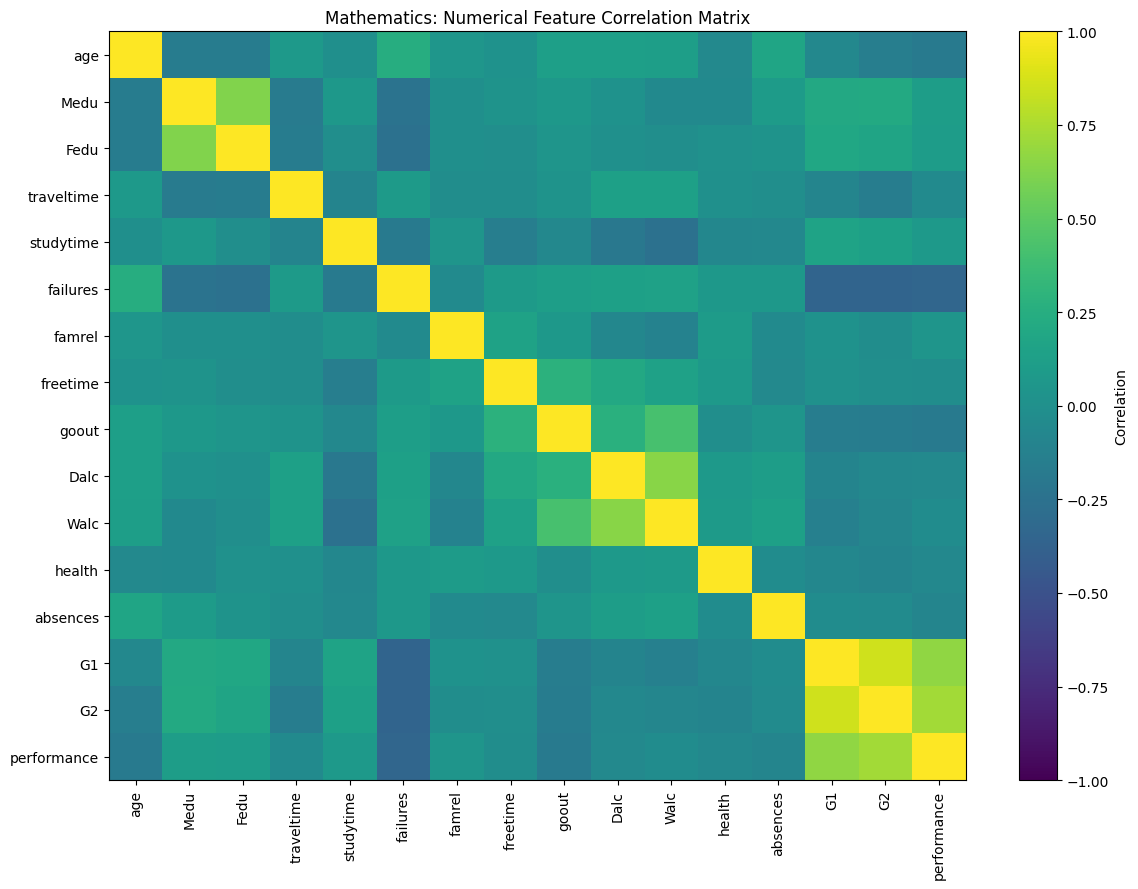


Portuguese: numerical feature correlations


,age,Medu,Fedu,traveltime,studytime,failures,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,performance
age,1.00,-0.11,-0.12,0.03,-0.01,0.32,-0.02,-0.00,0.11,0.13,0.09,-0.01,0.15,-0.17,-0.11,-0.11
Medu,-0.11,1.00,0.65,-0.27,0.10,-0.17,0.02,-0.02,0.01,-0.01,-0.02,0.00,-0.01,0.26,0.26,0.14
Fedu,-0.12,0.65,1.00,-0.21,0.05,-0.17,0.02,0.01,0.03,0.00,0.04,0.04,0.03,0.22,0.23,0.15
traveltime,0.03,-0.27,-0.21,1.00,-0.06,0.10,-0.01,0.00,0.06,0.09,0.06,-0.05,-0.01,-0.15,-0.15,-0.06
studytime,-0.01,0.10,0.05,-0.06,1.00,-0.15,-0.00,-0.07,-0.08,-0.14,-0.21,-0.06,-0.12,0.26,0.24,0.17
failures,0.32,-0.17,-0.17,0.10,-0.15,1.00,-0.06,0.11,0.05,0.11,0.08,0.04,0.12,-0.38,-0.39,-0.38
famrel,-0.02,0.02,0.02,-0.01,-0.00,-0.06,1.00,0.13,0.09,-0.08,-0.09,0.11,-0.09,0.05,0.09,0.04
freetime,-0.00,-0.02,0.01,0.00,-0.07,0.11,0.13,1.00,0.35,0.11,0.12,0.08,-0.02,-0.09,-0.11,-0.09
goout,0.11,0.01,0.03,0.06,-0.08,0.05,0.09,0.35,1.00,0.25,0.39,-0.02,0.09,-0.07,-0.08,-0.07
Dalc,0.13,-0.01,0.00,0.09,-0.14,0.11,-0.08,0.11,0.25,1.00,0.62,0.06,0.17,-0.20,-0.19,-0.12


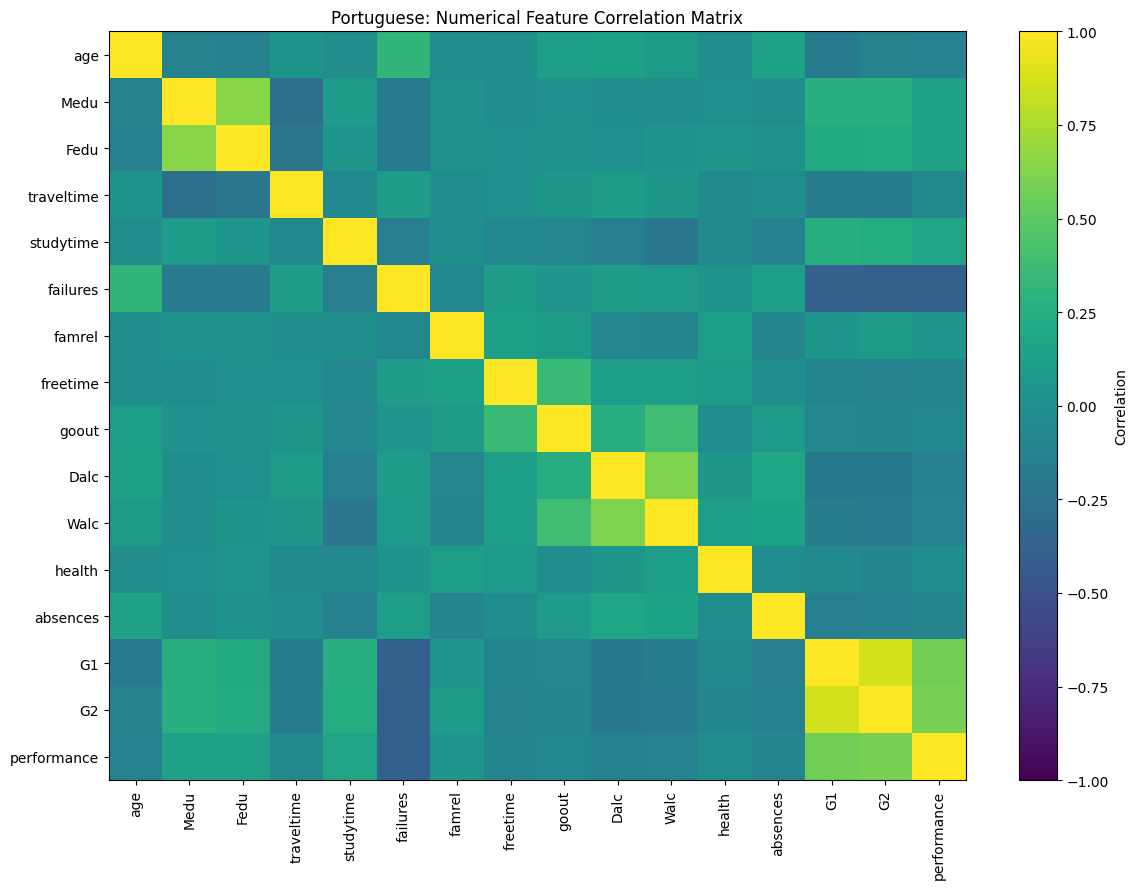

In [13]:

for name, df in datasets.items():
    numeric_df = df.select_dtypes(include="number")

    # G3 defines the target, so exclude it from this predictor-focused view.
    correlation_df = numeric_df.drop(
        columns=["G3"],
        errors="ignore"
    )

    correlations = correlation_df.corr()

    print(f"\n{name}: numerical feature correlations")
    display(correlations.round(2))

    # Plot the correlation matrix using Matplotlib only.
    fig, ax = plt.subplots(figsize=(12, 9))

    image = ax.imshow(
        correlations,
        aspect="auto",
        vmin=-1,
        vmax=1
    )

    ax.set_xticks(range(len(correlations.columns)))
    ax.set_xticklabels(
        correlations.columns,
        rotation=90
    )

    ax.set_yticks(range(len(correlations.index)))
    ax.set_yticklabels(correlations.index)

    ax.set_title(f"{name}: Numerical Feature Correlation Matrix")
    fig.colorbar(image, ax=ax, label="Correlation")
    plt.tight_layout()
    plt.show()


In [14]:

summary_rows = []

for name, df in datasets.items():
    at_risk_count = int((df["performance"] == 0).sum())
    pass_count = int((df["performance"] == 1).sum())

    summary_rows.append({
        "Dataset": name,
        "Total Students": len(df),
        "At Risk": at_risk_count,
        "Pass": pass_count,
        "At Risk (%)": round(at_risk_count / len(df) * 100, 2),
        "Pass (%)": round(pass_count / len(df) * 100, 2),
        "Mean G3": round(df["G3"].mean(), 2),
        "Median G3": round(df["G3"].median(), 2),
        "Duplicate Rows": int(df.duplicated().sum())
    })

eda_summary = pd.DataFrame(summary_rows)

display(eda_summary)

# Save the summary table
RESULTS_DIR = PROJECT_DIR / "results" / "tables"
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

summary_path = RESULTS_DIR / "eda_summary.csv"
eda_summary.to_csv(summary_path, index=False)

print("EDA summary saved to:", summary_path)


,Dataset,Total Students,At Risk,Pass,At Risk (%),Pass (%),Mean G3,Median G3,Duplicate Rows
0,Mathematics,395,130,265,32.91,67.09,10.42,11.0,0
1,Portuguese,649,100,549,15.41,84.59,11.91,12.0,0


EDA summary saved to: e:\PROJECTS\Mini Project\Project\Student-Performance-Prediction\results\tables\eda_summary.csv


In [15]:

for name, df in datasets.items():
    assert len(df) > 0
    assert "performance" in df.columns
    assert df["performance"].notna().all()
    assert set(df["performance"].unique()).issubset({0, 1})
    assert (df["performance"] == (df["G3"] >= 10)).all()

print("EDA data validation passed for both datasets.")
print("Target-labeled datasets:")
print("-", math_target_path)
print("-", por_target_path)
print("Summary table:")
print("-", summary_path)


EDA data validation passed for both datasets.
Target-labeled datasets:
- e:\PROJECTS\Mini Project\Project\Student-Performance-Prediction\data\processed\student_mat_target.csv
- e:\PROJECTS\Mini Project\Project\Student-Performance-Prediction\data\processed\student_por_target.csv
Summary table:
- e:\PROJECTS\Mini Project\Project\Student-Performance-Prediction\results\tables\eda_summary.csv
